In [1]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np


Open data and read it

Hansen

In [2]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

GLC

National parks

In [3]:
path_GLC_E25N70 = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E20-E25/GLC_FCS30D_20002022_E25N70_Annual.tif'

In [4]:
path_GLC_110W60N = 'C:/Users/minttu/Documents/GLC_FCS30D_data\GLC_FCS30D_19852022maps_W105-W110/GLC_FCS30D_20002022_W110N60_Annual.tif'

Mountain top

In [5]:
path_GLC_90E25N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E90-E95/GLC_FCS30D_20002022_E90N25_Annual.tif'

In [6]:
path_GLC_5E50N = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E0-E5/GLC_FCS30D_20002022_E5N50_Annual.tif'

Ice sheet

In [7]:
path_GLC_10E80S = 'C:/Users/minttu/Documents/GLC_FCS30D_data/GLC_FCS30D_19852022maps_E10-E15/GLC_FCS30D_20002022_E10N80_Annual.tif'

Open Hansen data

In [68]:
LCHansen2000 = rasterio.open(path_LC_Hansen)

In [8]:
LCHansen20002 = rioxarray.open_rasterio(path_LC_Hansen)

Read GLC data as xarray

In [9]:
GLC_FCS302000E25N70 = rioxarray.open_rasterio(path_GLC_E25N70)

In [10]:
GLC_FCS302000W110N60 = rioxarray.open_rasterio(path_GLC_110W60N)

In [11]:
GLC_FCS302000E90N25 = rioxarray.open_rasterio(path_GLC_90E25N)

In [12]:
GLC_FCS302000E5N50 = rioxarray.open_rasterio(path_GLC_5E50N)

In [13]:
GLC_FCS30200010E80S = rioxarray.open_rasterio(path_GLC_10E80S)

Select year 2000

In [14]:
GLC_FCS302000E25N70band1 = GLC_FCS302000E25N70.sel(band=1)

In [15]:
GLC_FCS302000W110N60band1 = GLC_FCS302000W110N60.sel(band=1)

In [16]:
GLC_FCS302000E90N25band1 = GLC_FCS302000E90N25.sel(band=1)

In [17]:
GLC_FCS302000E5N50band1 = GLC_FCS302000E5N50.sel(band=1)

In [18]:
GLC_FCS30200010E80Sband1 = GLC_FCS30200010E80S.sel(band=1)

## LH classification

Tree cover, broadleaved, evergreen, closed to open (>15%) 50
Tree cover, broadleaved, deciduous, closed to open (>15%) 60
Tree cover, broadleaved, deciduous, closed (>40%) 61
Tree cover, broadleaved, deciduous, open (15 – 40%) 62
Tree cover, needle leaved, evergreen, closed to open (>15%) 70
Tree cover, needle leaved, evergreen, closed (>40%) 71
Tree cover, needle leaved, evergreen, open (15 – 40%) 72
Tree cover needle leaved deciduous, closed to open (>15%) 80
Tree cover needle leaved deciduous, closed (>40%) 81
Tree cover needle leaved deciduous, open (15 – 40%) 82
Tree cover, mixed leaf type (broadleaved and needle leaved) 90
Filled_value, water 210

## GLC classification

  'Open_evergreen_broadleaved_forest', 51
  'Closed_evergreen_broadleaved_forest', 52
  'Open_deciduous_broadleaved_forest', 61
  'Closed_deciduous_broadleaved_forest', 62
  'Open_evergreen_needle_leaved_forest', 71
  'Closed_evergreen_needle_leaved_forest', 72
  'Open_deciduous_needle_leaved_forest', 81
  'Closed_deciduous_needle_leaved_forest',  82
  'Open_mixed_leaf_forest', 91
  'Closed_mixed_leaf_forest', 92
  grassland, 130
  sparse vegetation, 150
  flooded flat, 183
  saline, 184
  Bare_areas 200
  'Consolidated_bare_areas', 201
  Unconsolidated_bare_areas', 202
  'Water_body', 210
  'Permanent_ice_and_snow', 220
  'Filled_value' 0

## Check coordinate systems

In [18]:
LCHansen2000.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

In [19]:
GLC_FCS302000E25N70band1.rio.crs

CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]')

## Plot forest areas global Hansen

## Hansen Select areas with forest

Show bounds

In [36]:
bounds = LCHansen2000.bounds
print(bounds)

BoundingBox(left=-180.0, bottom=-90.0, right=180.0, top=90.0)


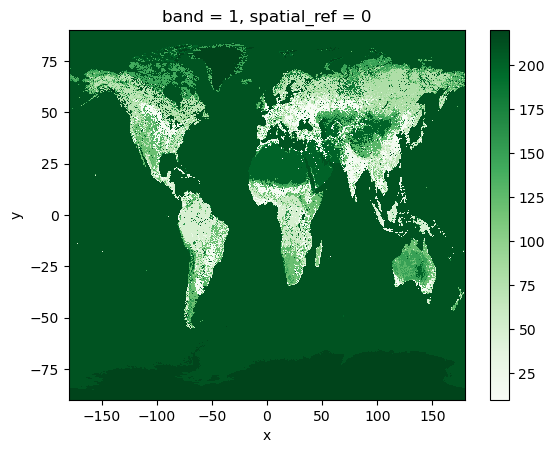

In [54]:
LCHansen20002.plot(cmap="Greens")

In [19]:
LCHansen20002forest = (LCHansen20002 >= 50) & (LCHansen20002 <= 90)

In [23]:
LCHansen20002forest

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 26MB
array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]],
      shape=(1, 3600, 7200))
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 89.97 89.92 89.88 ... -89.88 -89.93 -89.98
  * x            (x) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

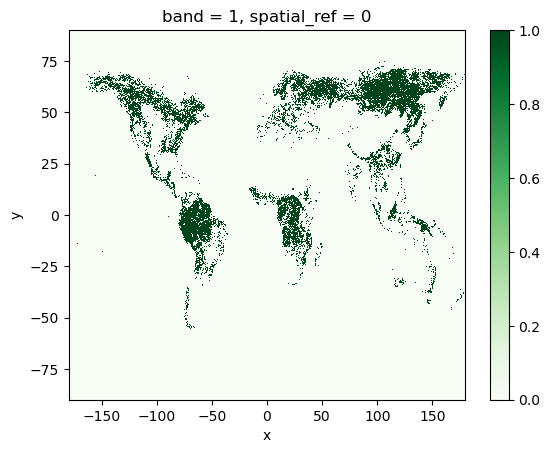

In [56]:
LCHansen20002forest.plot(cmap="Greens")

## Select areas with snow and ice Hansen

In [20]:
maskLCHansen20002snow = (LCHansen20002 == 210)

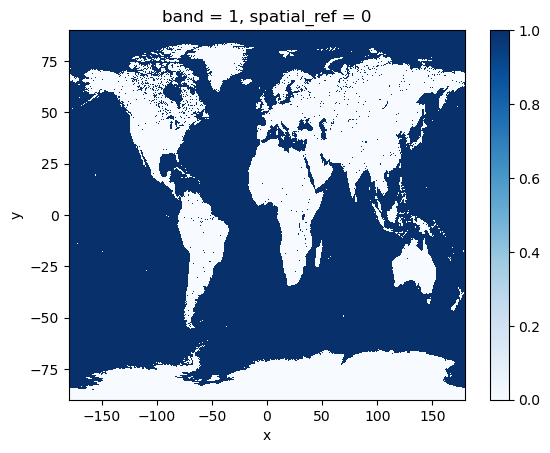

In [158]:
maskLCHansen20002snow.plot(cmap='Blues')

## GLC Select areas with forest

In [21]:
maskGLC_FCS302000E25N70band1 = (GLC_FCS302000E25N70band1 >= 51) & (GLC_FCS302000E25N70band1 <= 92)

In [22]:
maskGLC_FCS302000W110N60band1 = (GLC_FCS302000W110N60band1 >= 51) & (GLC_FCS302000W110N60band1 <= 92)

## GLC Select areas with snow and ice

In [86]:
GLC_FCS302000E90N25band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
array([[ 20,  20, 200, ..., 200, 210, 210],
       [ 20,  20,  20, ..., 210, 210, 210],
       [ 20,  20,  20, ..., 210, 210, 210],
       ...,
       [210, 210, 210, ..., 183, 183, 200],
       [210, 210, 210, ..., 200, 183,  10],
       [200, 200, 200, ...,   0,   0,   0]],
      shape=(18554, 18554), dtype=uint8)
Coordinates:
  * y            (y) float64 148kB 25.0 25.0 25.0 25.0 ... 20.0 20.0 20.0 20.0
  * x            (x) float64 148kB 90.0 90.0 90.0 90.0 ... 95.0 95.0 95.0 95.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [64]:
GLC_FCS302000E5N50band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
array([[ 51,  51,  51, ...,  11,  11,   0],
       [ 72,  72,  72, ...,  11,  12,   0],
       [ 72,  72,  72, ...,  11,  11,   0],
       ...,
       [ 11, 190, 190, ...,  20,  20,   0],
       [ 11, 190,  11, ...,  11,  11,   0],
       [  0,   0,   0, ...,   0,   0,   0]],
      shape=(18554, 18554), dtype=uint8)
Coordinates:
  * y            (y) float64 148kB 50.0 50.0 50.0 50.0 ... 45.0 45.0 45.0 45.0
  * x            (x) float64 148kB 5.0 5.0 5.001 5.001 ... 9.999 10.0 10.0 10.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [151]:
maskGLC_FCS302000E90N25band1 = (GLC_FCS302000E90N25band1 == 210) | (GLC_FCS302000E90N25band1 == 220) & (GLC_FCS302000E90N25band1 == 0)

In [27]:
maskGLC_FCS302000E5N50band1 = (GLC_FCS302000E5N50band1 == 210) & (GLC_FCS302000E5N50band1 == 220) & (GLC_FCS302000E5N50band1 == 0) & (GLC_FCS302000E5N50band1 == 184)

In [72]:
maskGLC_FCS30200010E80Sband1 = (GLC_FCS30200010E80Sband1 == 150) | (GLC_FCS30200010E80Sband1 == 130) | (GLC_FCS30200010E80Sband1 == 210) | (GLC_FCS30200010E80Sband1 == 220) | (GLC_FCS30200010E80Sband1 == 0) | (GLC_FCS30200010E80Sband1 == 202) | (GLC_FCS30200010E80Sband1 == 201) | (GLC_FCS30200010E80Sband1 == 200) | (GLC_FCS30200010E80Sband1 == 184) | (GLC_FCS30200010E80Sband1 == 183)

# Mask Hansen E25 N70

In [24]:
minx, miny, maxx, maxy = 25.0, 64.99979746553392, 30.000202534466077, 70.0

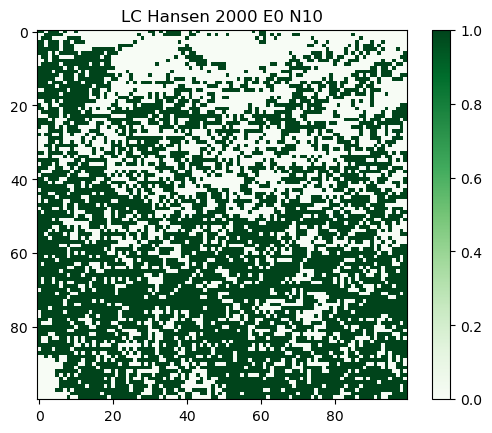

In [25]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

maskLC_HansenE25N70 = (subset >= 50) & (subset <= 90) 
# Apply mask (set others to NaN for visualization)
filteredLCHansen2000E25N70 = np.where(maskLC_HansenE25N70, subset, np.nan)

pyplot.imshow(maskLC_HansenE25N70, cmap='Greens')
pyplot.title("LC Hansen 2000 E0 N10")
pyplot.colorbar()

# Resample GLC E25 N70

In [26]:
LCHansen2000E25N70 = rioxarray.open_rasterio(path_LC_Hansen)

left → min X (longitude or easting)
right → max X
bottom → min Y (latitude or northing)
top → max Y

In [35]:
bounds = GLC_FCS302000E25N70band1.rio.bounds()
print(bounds)

(25.0, 64.99979746553392, 30.000202534466077, 70.0)


In [27]:
croppedLCHansen2000E25N70 = LCHansen2000E25N70.rio.clip_box(
    minx=25.0,
    miny=64.99979746553392,
    maxx=30.000202534466077,
    maxy=70.0
)

In [28]:
croppedLCHansen2000E25N70

<xarray.DataArray (band: 1, y: 101, x: 101)> Size: 41kB
[10201 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 808B 69.97 69.92 69.88 69.82 ... 65.07 65.02 64.97
  * x            (x) float64 808B 25.03 25.08 25.13 25.18 ... 29.93 29.98 30.03
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [119]:
maskGLC_FCS302000E25N70band1

NameError: name 'maskGLC_FCS302000E25N70band1' is not defined

In [30]:
maskGLC_FCS302000E25N70band1int = maskGLC_FCS302000E25N70band1.astype(int)

# Resample with interp

In [31]:
maskGLC_FCS302000E25N70band1int_interp = maskGLC_FCS302000E25N70band1int.interp(x = croppedLCHansen2000E25N70['x'], y = croppedLCHansen2000E25N70['y'], method='nearest')

In [32]:
maskGLC_FCS302000E25N70band1int_interp

<xarray.DataArray (y: 101, x: 101)> Size: 82kB
array([[ 0.,  0.,  0., ...,  0.,  0., nan],
       [ 1.,  0.,  1., ...,  0.,  0., nan],
       [ 0.,  1.,  1., ...,  0.,  0., nan],
       ...,
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(101, 101))
Coordinates:
  * y            (y) float64 808B 69.97 69.92 69.88 69.82 ... 65.07 65.02 64.97
  * x            (x) float64 808B 25.03 25.08 25.13 25.18 ... 29.93 29.98 30.03
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

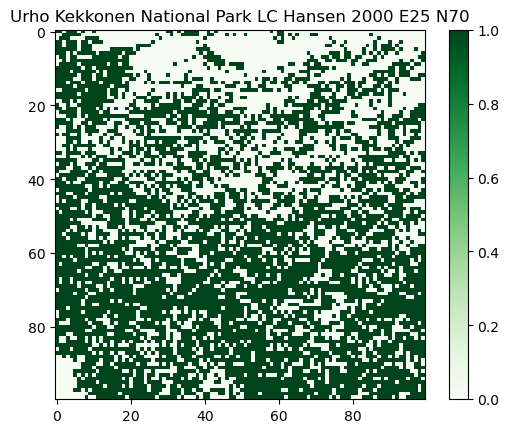

In [33]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

maskLC_HansenE25N70 = (subset >= 50) & (subset <= 90) 
# Apply mask (set others to NaN for visualization)
filteredLC_HansenE25N70 = np.where(maskLC_HansenE25N70, subset, np.nan)

pyplot.imshow(maskLC_HansenE25N70, cmap='Greens')
pyplot.title("Urho Kekkonen National Park LC Hansen 2000 E25 N70")
pyplot.colorbar()

Text(0.5, 1.0, 'Urho Kekkonen National Park GLC FCS30 2000 E25 N70')

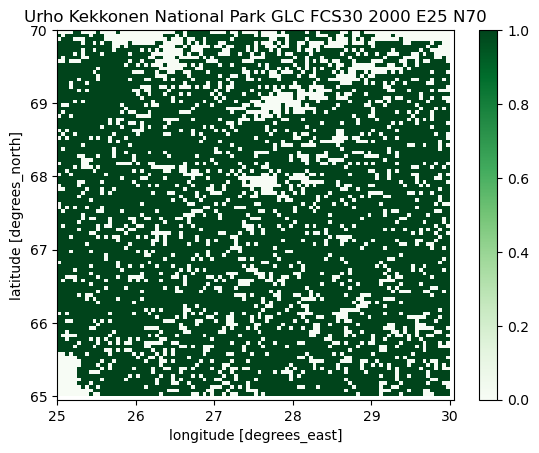

In [34]:
maskGLC_FCS302000E25N70band1int_interp.plot(cmap="Greens")
pyplot.title("Urho Kekkonen National Park GLC FCS30 2000 E25 N70")

# Mask Hansen W110 N60

In [68]:
minx, miny, maxx, maxy = -110.0, 54.999797465533916, -104.99979746553392, 60.0

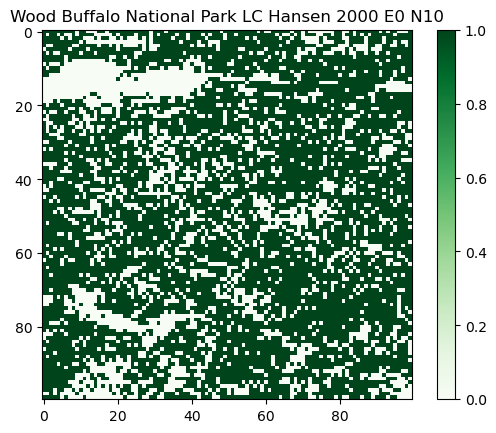

In [70]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

maskLC_HansenW110N60 = (subset >= 50) & (subset <= 90) 
# Apply mask (set others to NaN for visualization)
filteredLCHansen2000W110N60 = np.where(maskLC_HansenW110N60, subset, np.nan)

pyplot.imshow(maskLC_HansenW110N60, cmap='Greens')
pyplot.title("Wood Buffalo National Park LC Hansen 2000 E0 N10")
pyplot.colorbar()

# Resample GLC W110 N60

In [66]:
bounds = GLC_FCS302000W110N60band1.rio.bounds()
print(bounds)

(-110.0, 54.999797465533916, -104.99979746553392, 60.0)


In [67]:
croppedLCHansen2000W110N60 = LCHansen20003.rio.clip_box(
    minx=-110.0,
    miny=54.999797465533916,
    maxx=-104.99979746553392,
    maxy=60.0
)

In [71]:
maskGLC_FCS302000W110N60band1int = maskGLC_FCS302000W110N60band1.astype(int)

# Resample with interp

In [72]:
maskGLC_FCS302000W110N60band1int_interp = maskGLC_FCS302000W110N60band1int.interp(x = croppedLCHansen2000W110N60['x'], y = croppedLCHansen2000W110N60['y'], method='nearest')

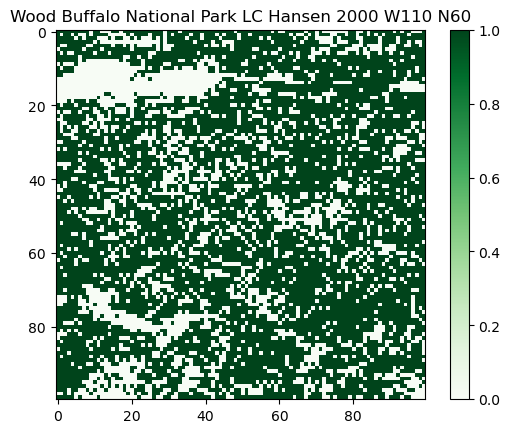

In [73]:
with rasterio.open(path_LC_Hansen) as src:
    window = from_bounds(minx, miny, maxx, maxy, src.transform)
    subset = src.read(1, window=window)

maskLC_HansenW110N60 = (subset >= 50) & (subset <= 90) 
# Apply mask (set others to NaN for visualization)
filteredLC_HansenW110N60 = np.where(maskLC_HansenW110N60, subset, np.nan)

pyplot.imshow(maskLC_HansenW110N60, cmap='Greens')
pyplot.title("Wood Buffalo National Park LC Hansen 2000 W110 N60")
pyplot.colorbar()

Text(0.5, 1.0, 'Urho Kekkonen National Park GLC FCS30 2000 W110 N60')

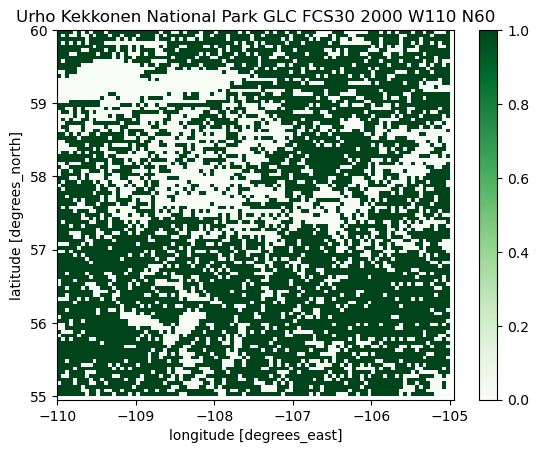

In [74]:
maskGLC_FCS302000W110N60band1int_interp.plot(cmap="Greens")
pyplot.title("Urho Kekkonen National Park GLC FCS30 2000 W110 N60")

# Mask E90 N25

In [16]:
bounds = GLC_FCS302000E90N25band1.rio.bounds()
print(bounds)

NameError: name 'GLC_FCS302000E90N25band1' is not defined

In [17]:
minx, miny, maxx, maxy = 90.0, 19.999797465533923, 95.00020253446608, 25.0

Text(0.5, 1.0, 'Mount Everest LC Hansen 2000 E90 N25')

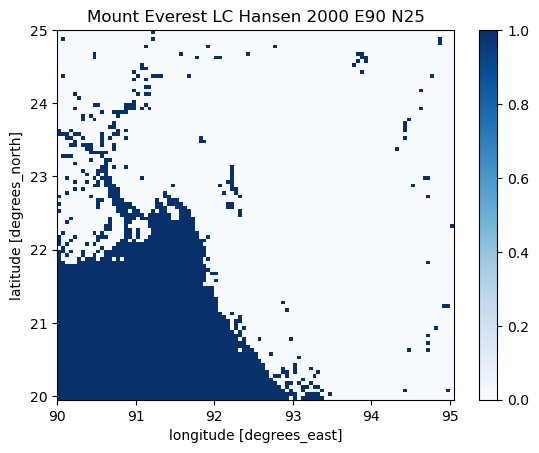

In [159]:
subset = maskLCHansen20002snow.rio.clip_box(
    minx=90.0,
    miny=19.999797465533923,
    maxx=95.00020253446608,
    maxy=25.0
)
subset.plot(cmap='Blues')
pyplot.title("Mount Everest LC Hansen 2000 E90 N25")

# Resample GLC E90 N25

In [145]:
maskGLC_FCS302000E90N25band1

<xarray.DataArray (y: 18554, x: 18554)> Size: 344MB
array([[False, False, False, ..., False,  True,  True],
       [False, False, False, ...,  True,  True,  True],
       [False, False, False, ...,  True,  True,  True],
       ...,
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [False, False, False, ..., False, False, False]],
      shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 25.0 25.0 25.0 25.0 ... 20.0 20.0 20.0 20.0
  * x            (x) float64 148kB 90.0 90.0 90.0 90.0 ... 95.0 95.0 95.0 95.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [146]:
maskGLC_FCS302000E90N25band1int = maskGLC_FCS302000E90N25band1.astype(int)

In [147]:
maskGLC_FCS302000E90N25band1int

<xarray.DataArray (y: 18554, x: 18554)> Size: 3GB
array([[0, 0, 0, ..., 0, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 0, 0, 0],
       [1, 1, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(18554, 18554))
Coordinates:
  * y            (y) float64 148kB 25.0 25.0 25.0 25.0 ... 20.0 20.0 20.0 20.0
  * x            (x) float64 148kB 90.0 90.0 90.0 90.0 ... 95.0 95.0 95.0 95.0
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

# Resample with interp

In [148]:
croppedLCHansen2000E90N25 = LCHansen20002.rio.clip_box(
    minx=90.0,
    miny=19.999797465533923,
    maxx=95.00020253446608,
    maxy=25.0
)

In [149]:
maskGLC_FCS302000E90N25band1int_interp = maskGLC_FCS302000E90N25band1int.interp(x = croppedLCHansen2000E90N25['x'], y = croppedLCHansen2000E90N25['y'], method='nearest')

# Plot E90 N25

Text(0.5, 1.0, 'Mount Everest LC Hansen 2000 E90 N25')

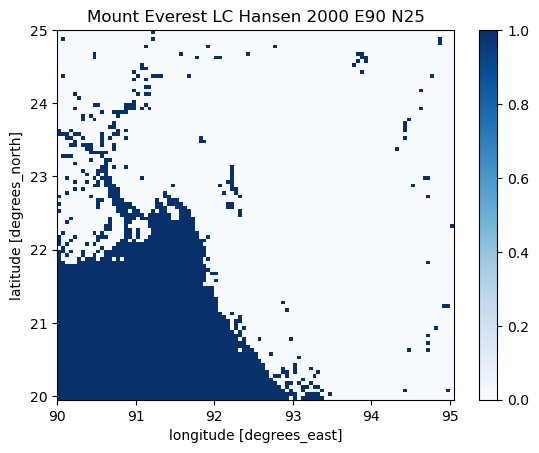

In [156]:
subset = maskLCHansen20002snow.rio.clip_box(
    minx=90.0,
    miny=19.999797465533923,
    maxx=95.00020253446608,
    maxy=25.0
)
subset.plot(cmap='Blues')
pyplot.title("Mount Everest LC Hansen 2000 E90 N25")

Text(0.5, 1.0, 'Mount Everest GLC FCS30 2000 E90 N25')

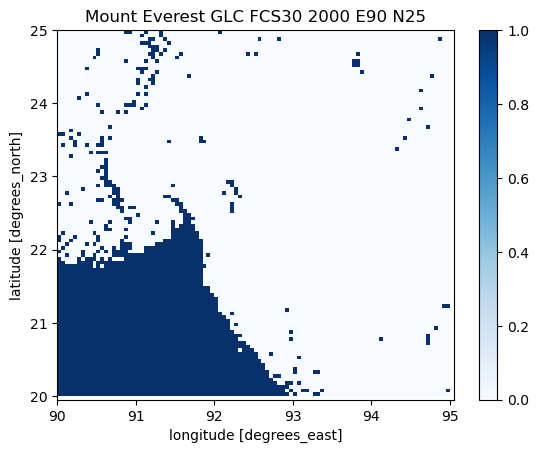

In [157]:
maskGLC_FCS302000E90N25band1int_interp.plot(cmap="Blues")
pyplot.title("Mount Everest GLC FCS30 2000 E90 N25")

# Mask E5N 50

In [28]:
bounds = GLC_FCS302000E5N50band1.rio.bounds()
print(bounds)

(5.0, 44.999797465533916, 10.00020253446608, 50.0)


Text(0.5, 1.0, ' LC Hansen 2000 E5 N50')

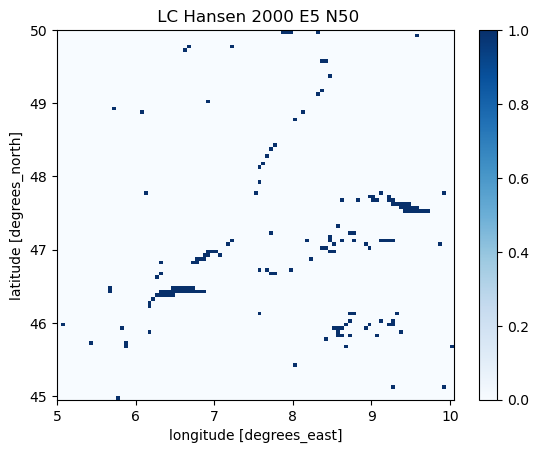

In [29]:
subset = maskLCHansen20002snow.rio.clip_box(
    minx=5.0,
    miny=44.999797465533916,
    maxx=10.00020253446608,
    maxy=50.0
)
subset.plot(cmap='Blues')
pyplot.title(" LC Hansen 2000 E5 N50")

In [73]:
maskGLC_FCS302000E5N50band1int = maskGLC_FCS302000E5N50band1.astype(int)

# Resample with interp

In [74]:
croppedLCHansen2000E5N50 = maskLCHansen20002snow.rio.clip_box(
    minx=5.0,
    miny=44.999797465533916,
    maxx=10.00020253446608,
    maxy=50.0
)

In [75]:
maskGLC_FCS302000E5N505band1int_interp = maskGLC_FCS302000E5N50band1int.interp(x = croppedLCHansen2000E5N50['x'], y = croppedLCHansen2000E5N50['y'], method='nearest')

Text(0.5, 1.0, 'Mont Blanc LC Hansen 2000 E5 N50')

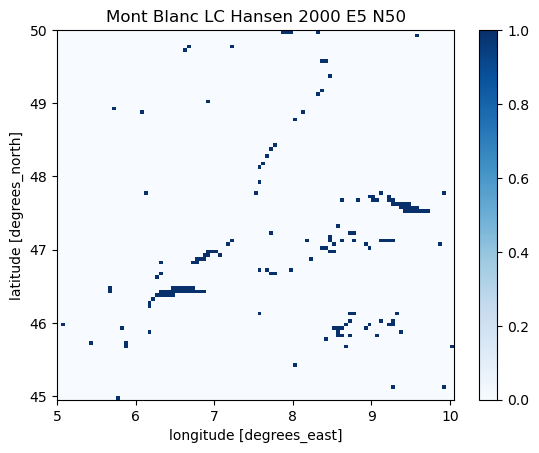

In [76]:
croppedLCHansen2000E5N50.plot(cmap='Blues')
pyplot.title("Mont Blanc LC Hansen 2000 E5 N50")

Text(0.5, 1.0, 'Mont Blanc GLC FCS30 2000 E5 N50')

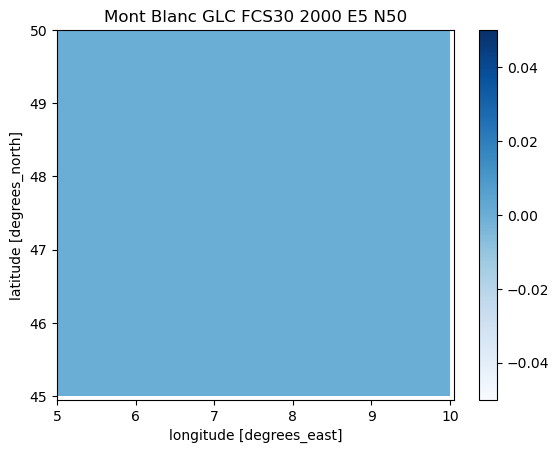

In [77]:
maskGLC_FCS302000E5N505band1int_interp.plot(cmap="Blues")
pyplot.title("Mont Blanc GLC FCS30 2000 E5 N50")

# Mask Hansen E10 N80

In [59]:
bounds = GLC_FCS30200010E80Sband1.rio.bounds()
print(bounds)

(10.0, 74.99979746553392, 15.000202534466082, 80.0)


Text(0.5, 1.0, 'Antarctica LC Hansen 2000 E10 S80')

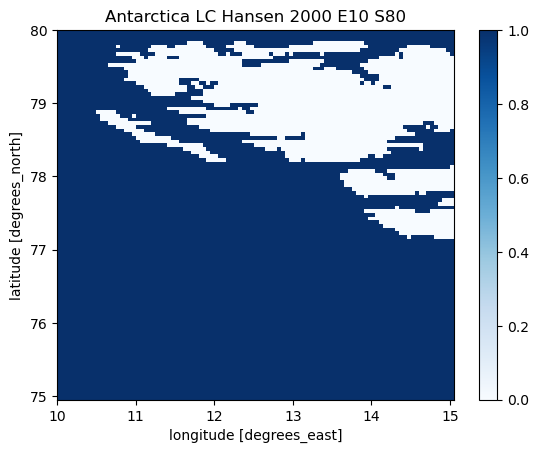

In [60]:
subset = maskLCHansen20002snow.rio.clip_box(
    minx=10.0,
    miny=74.99979746553392,
    maxx=15.000202534466082,
    maxy=80.0
)
subset.plot(cmap='Blues')
pyplot.title("Antarctica LC Hansen 2000 E10 S80")

# Resample E10 S80

In [78]:
maskGLC_FCS30200010E80Sband1int = maskGLC_FCS30200010E80Sband1.astype(int)

In [79]:
croppedLCHansen200010E80S = maskLCHansen20002snow.rio.clip_box(
    minx=10.0,
    miny=74.99979746553392,
    maxx=15.000202534466082,
    maxy=80.0
)

In [80]:
maskGLC_FCS30200010E80Sband_interp = maskGLC_FCS30200010E80Sband1int.interp(x = croppedLCHansen200010E80S['x'], y = croppedLCHansen200010E80S['y'], method='nearest')

# Plot E10 S80

Text(0.5, 1.0, 'Antarcica LC Hansen 2000 E10 N80')

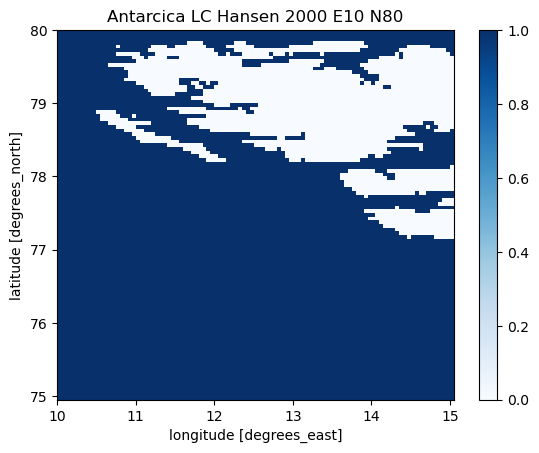

In [81]:
croppedLCHansen200010E80S.plot(cmap='Blues')
pyplot.title("Antarcica LC Hansen 2000 E10 N80")

Text(0.5, 1.0, 'Antarcica LC GLC FCS30 2000 E10 N80')

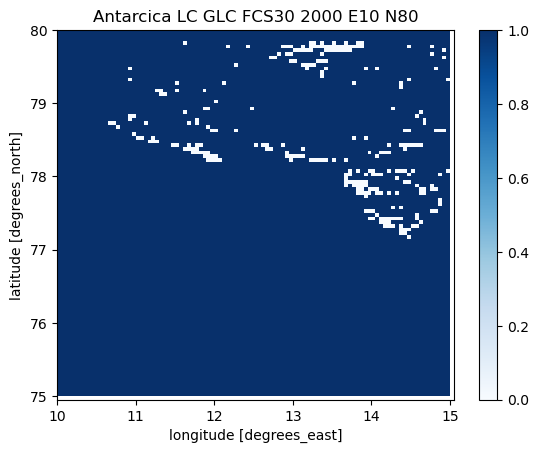

In [82]:
maskGLC_FCS30200010E80Sband_interp.plot(cmap="Blues")
pyplot.title("Antarcica LC GLC FCS30 2000 E10 N80")

# Compare the LC maps

## E25N70

In [81]:
maskLC_HansenE25N70.astype(int)

array([[1, 1, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       [0, 1, 1, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 1],
       [0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 1]], shape=(100, 100))

In [80]:
maskGLC_FCS302000E25N70band1int_interp

<xarray.DataArray (y: 101, x: 101)> Size: 82kB
array([[ 0.,  0.,  0., ...,  0.,  0., nan],
       [ 1.,  0.,  1., ...,  0.,  0., nan],
       [ 0.,  1.,  1., ...,  0.,  0., nan],
       ...,
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(101, 101))
Coordinates:
  * y            (y) float64 808B 69.97 69.92 69.88 69.82 ... 65.07 65.02 64.97
  * x            (x) float64 808B 25.03 25.08 25.13 25.18 ... 29.93 29.98 30.03
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [83]:
maskGLC_FCS302000E25N70band1int_interparr = maskGLC_FCS302000E25N70band1int_interp.values

In [84]:
maskGLC_FCS302000E25N70band1int_interparr

array([[ 0.,  0.,  0., ...,  0.,  0., nan],
       [ 1.,  0.,  1., ...,  0.,  0., nan],
       [ 0.,  1.,  1., ...,  0.,  0., nan],
       ...,
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [ 0.,  0.,  0., ...,  1.,  1., nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(101, 101))

In [86]:
maskGLC_FCS302000E25N70band1int_interparr = maskGLC_FCS302000E25N70band1int_interparr[:-1, :-1]

## W110N60

In [76]:
maskGLC_FCS302000W110N60band1int_interparr = maskGLC_FCS302000W110N60band1int_interp.values

In [77]:
maskGLC_FCS302000W110N60band1int_interparr = maskGLC_FCS302000W110N60band1int_interparr[:-1, :-1]

# Count differences

## E25N70

In [91]:
differences = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr != maskLC_HansenE25N70))

In [93]:
differences

2913

In [99]:
same = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr == maskLC_HansenE25N70))

In [100]:
same

7087

In [103]:
all = differences+same

In [104]:
all

10000

## Percentage of same and different

In [114]:
same/all

0.7087

In [105]:
differences/all

0.2913

In [98]:
Forest = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr == 1))

NameError: name 'maskGLC_FCS302000E25N70band1int_interparr' is not defined

In [ ]:
Forest

In [ ]:
Forest2 = int(np.sum(maskGLC_FCS302000E25N70band1int_interparr == 1))

In [ ]:
Forest2

## Percentage of forest

In [ ]:
(Forest-Forest2)/all

## W110N60

In [78]:
differences = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr != maskLC_HansenW110N60))

In [ ]:
differences

In [80]:
same = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr == maskLC_HansenW110N60))

In [81]:
same

7364

In [82]:
all = differences+same

In [83]:
all

10000

## Percentage of same and different

In [ ]:
same/all

In [85]:
differences/all

0.2636

In [89]:
Forest = int(np.sum(maskGLC_FCS302000W110N60band1int_interparr == 1))

In [90]:
Forest

6372

In [91]:
Forest2 = int(np.sum(maskLC_HansenW110N60))

In [92]:
Forest2

6874

## Percentage of forest

In [ ]:
(Forest-Forest2)/all